In [1]:
import os
import sys
import pickle
from pathlib import Path
from google.colab import drive
import torch
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights
from PIL import Image
import matplotlib.pyplot as plt

drive.mount('/content/drive')

DRIVE_DIR = Path('/content/drive/My Drive/Kelompok9') if Path('/content/drive/My Drive/Kelompok9').exists() else Path('/content/drive/MyDrive/Kelompok9')
LOCAL_DIR = Path('/content')
SRC_DIR = DRIVE_DIR / 'src'
FEAT_DIR = DRIVE_DIR / 'features'
CKPT_DIR = DRIVE_DIR / 'checkpoints'

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
if str(DRIVE_DIR) not in sys.path:
    sys.path.insert(0, str(DRIVE_DIR))

from model import CaptionDecoder

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
CKPT_NAME = 'best_E5_dhafin.pt' if (CKPT_DIR / 'best_E5_dhafin.pt').exists() else 'best_e5_dhafin.pt'
CHECKPOINT_PATH = CKPT_DIR / CKPT_NAME
VOCAB_PATH = FEAT_DIR / 'vocab.pkl'
BEAM_SIZE = 3
BEAM_ALPHA = 0.7
MAX_LEN = 30

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
def load_vocabulary(path):
    with open(path, 'rb') as f:
        data = pickle.load(f)
    word2idx = data['word2idx']
    idx2word = data['idx2word']
    if isinstance(idx2word, list):
        idx2word = {i: w for i, w in enumerate(idx2word)}
    return word2idx, idx2word

def build_encoder(device):
    weights = ResNet50_Weights.IMAGENET1K_V2
    base_model = resnet50(weights=weights)
    modules = list(base_model.children())[:-1]
    encoder = nn.Sequential(*modules)
    for param in encoder.parameters():
        param.requires_grad = False
    encoder.eval()
    return encoder.to(device)

def build_decoder(checkpoint_path, vocab_size, device):
    checkpoint = torch.load(checkpoint_path, map_location=device)
    state_dict = checkpoint.get('model_state_dict', checkpoint)
    hidden_size = state_dict['init_h.weight'].shape[0]
    feature_dim = state_dict['init_h.weight'].shape[1]
    embed_dim = state_dict['embedding.weight'].shape[1]
    model = CaptionDecoder(
        vocab_size=vocab_size,
        feature_dim=feature_dim,
        embed_dim=embed_dim,
        hidden_size=hidden_size,
        dropout_p=0.5,
        pad_idx=0
    )
    model.load_state_dict(state_dict, strict=True)
    model.eval()
    return model.to(device)

word2idx, idx2word = load_vocabulary(VOCAB_PATH)
encoder = build_encoder(DEVICE)
decoder = build_decoder(CHECKPOINT_PATH, len(word2idx), DEVICE)
preprocess_transform = ResNet50_Weights.IMAGENET1K_V2.transforms()

In [3]:
def load_and_preprocess_image(image_path, transform):
    image = Image.open(image_path).convert('RGB')
    tensor = transform(image)
    return tensor.unsqueeze(0)

def extract_visual_features(image_tensor, encoder, device):
    tensor = image_tensor.to(device)
    with torch.no_grad():
        feature = encoder(tensor)
        feature = torch.flatten(feature, 1)
    return feature

In [4]:
def decode_token_ids(token_ids, idx2word):
    words = [idx2word.get(i, '<unk>') for i in token_ids if i not in (0, 1, 2)]
    return ' '.join(words)

def predict_greedy(feature, decoder, max_len):
    return decoder.generate_greedy(feature, max_len=max_len)

def predict_beam(feature, decoder, beam_size, alpha, max_len):
    return decoder.generate_beam(feature, beam_size=beam_size, alpha=alpha, max_len=max_len)

def display_caption_result(image_path, greedy_caption, beam_caption):
    image = Image.open(image_path).convert('RGB')
    plt.figure(figsize=(9, 6))
    plt.imshow(image)
    plt.axis('off')
    title_text = f"Greedy: {greedy_caption}\nBeam Search: {beam_caption}"
    plt.title(title_text, fontsize=11, pad=12)
    plt.show()

def caption_image(image_path, encoder, decoder, transform, idx2word, device):
    image_tensor = load_and_preprocess_image(image_path, transform)
    feature = extract_visual_features(image_tensor, encoder, device)
    greedy_ids = predict_greedy(feature, decoder, MAX_LEN)
    beam_ids = predict_beam(feature, decoder, BEAM_SIZE, BEAM_ALPHA, MAX_LEN)
    greedy_text = decode_token_ids(greedy_ids, idx2word)
    beam_text = decode_token_ids(beam_ids, idx2word)
    display_caption_result(image_path, greedy_text, beam_text)
    return {'greedy': greedy_text, 'beam': beam_text}

custom_image_path = LOCAL_DIR / 'demo_sample.jpg'
if custom_image_path.exists():
    caption_image(
        custom_image_path,
        encoder,
        decoder,
        preprocess_transform,
        idx2word,
        DEVICE
    )

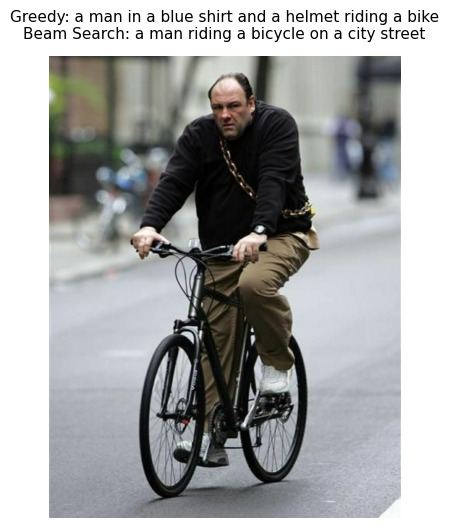

File Pengujian : demo_sample.jpeg
Hasil Greedy   : a man in a blue shirt and a helmet riding a bike
Hasil Beam     : a man riding a bicycle on a city street


In [5]:
from pathlib import Path

def resolve_target_image(path_candidates):
    for p in path_candidates:
        target = Path(p)
        if target.is_file():
            return target
    raise FileNotFoundError("Berkas citra uji tidak ditemukan pada direktori lokal.")

def format_demo_log(image_name, results):
    print(f"File Pengujian : {image_name}")
    print(f"Hasil Greedy   : {results['greedy']}")
    print(f"Hasil Beam     : {results['beam']}")

sample_candidates = [
    '/content/demo_sample.png',
    '/content/demo_sample.jpg',
    '/content/demo_sample.jpeg'
]

test_image_path = resolve_target_image(sample_candidates)
inference_results = caption_image(
    test_image_path,
    encoder,
    decoder,
    preprocess_transform,
    idx2word,
    DEVICE
)
format_demo_log(test_image_path.name, inference_results)

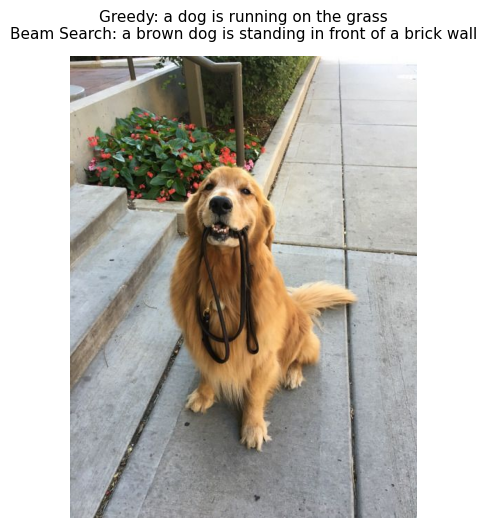

File Pengujian : demo_sample_2.jpeg
Hasil Greedy   : a dog is running on the grass
Hasil Beam     : a brown dog is standing in front of a brick wall


In [6]:
sample_candidates_2 = [
    LOCAL_DIR / 'demo_sample_2.png',
    LOCAL_DIR / 'demo_sample_2.jpg',
    LOCAL_DIR / 'demo_sample_2.jpeg'
]

test_image_path_2 = resolve_target_image(sample_candidates_2)
inference_results_2 = caption_image(
    test_image_path_2,
    encoder,
    decoder,
    preprocess_transform,
    idx2word,
    DEVICE
)
format_demo_log(test_image_path_2.name, inference_results_2)

In [7]:
import zipfile

def resolve_zip_source(drive_path):
    zip_path = drive_path / 'data' / 'flickr8.zip'
    if not zip_path.is_file():
        raise FileNotFoundError(f"Berkas arsip tidak ditemukan di: {zip_path}")
    return zip_path

def extract_dataset_archive(zip_path, target_dir):
    images_dir = target_dir / 'Images'
    if not images_dir.is_dir() or len(list(images_dir.glob('*.jpg'))) == 0:
        target_dir.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(zip_path, 'r') as archive:
            archive.extractall(target_dir)
    return images_dir

zip_archive_path = resolve_zip_source(DRIVE_DIR)
local_images_dir = extract_dataset_archive(zip_archive_path, LOCAL_DIR)

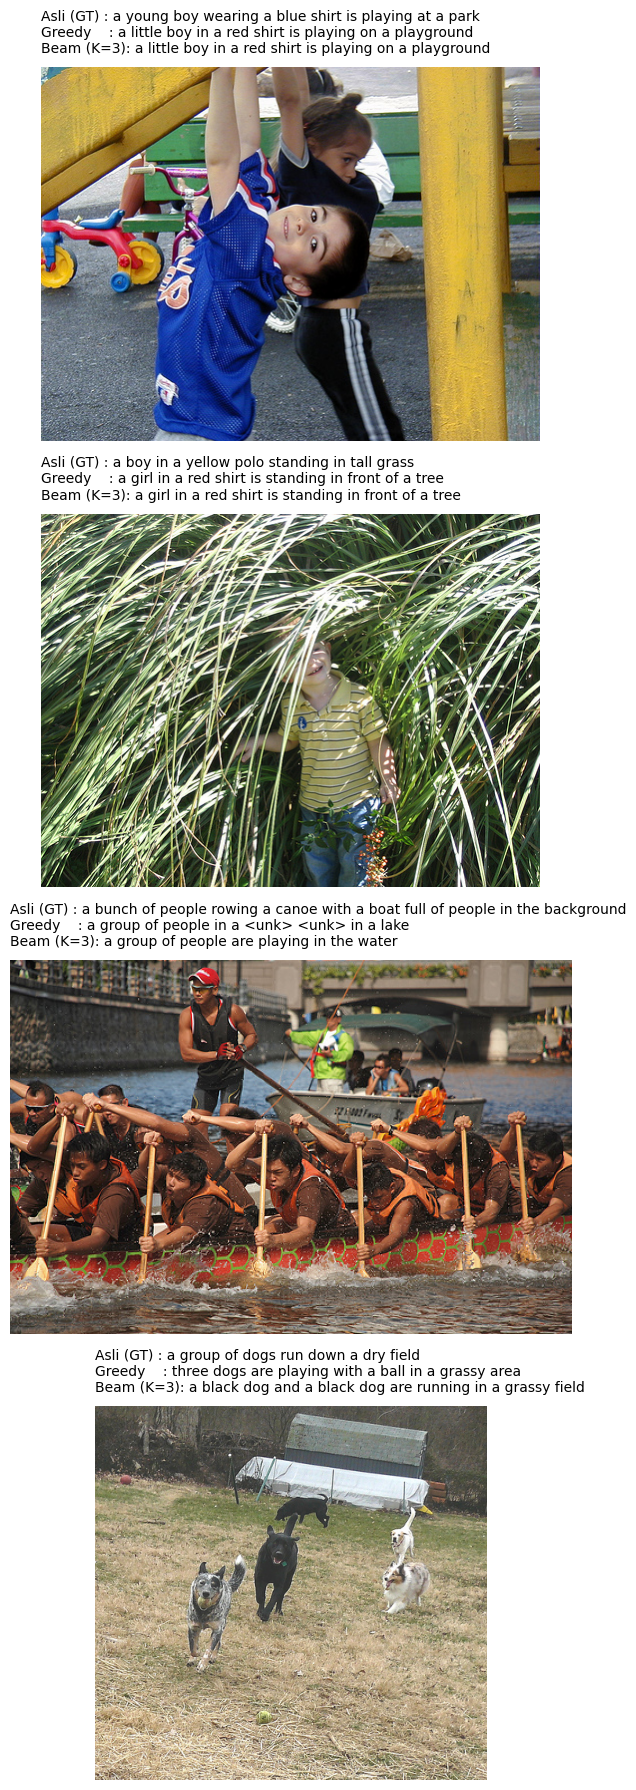

In [8]:
from dataset import get_eval_set

def load_validation_records(features_dir):
    image_names, feature_tensor, references = get_eval_set('val', features_dir=features_dir)
    return image_names, feature_tensor, references

def select_gallery_indices(total_items, num_display):
    step = total_items // num_display
    return [i * step for i in range(num_display)]

def format_caption_text(words):
    return ' '.join(words)

def generate_comparison_captions(feature, decoder, idx2word, max_len, beam_size, alpha):
    greedy_ids = decoder.generate_greedy(feature, max_len=max_len)
    beam_ids = decoder.generate_beam(feature, beam_size=beam_size, alpha=alpha, max_len=max_len)
    greedy_text = decode_token_ids(greedy_ids, idx2word)
    beam_text = decode_token_ids(beam_ids, idx2word)
    return greedy_text, beam_text

def locate_image_file(images_dir, image_name):
    direct_path = images_dir / image_name
    if direct_path.is_file():
        return direct_path
    nested_path = images_dir / 'Images' / image_name
    if nested_path.is_file():
        return nested_path
    raise FileNotFoundError(f"File gambar {image_name} tidak ditemukan.")

def render_gallery_panel(samples, decoder, idx2word, device, max_len, beam_size, alpha):
    num_samples = len(samples)
    fig, axes = plt.subplots(num_samples, 1, figsize=(10, 4.5 * num_samples))
    if num_samples == 1:
        axes = [axes]
    for ax, (img_path, feature, ref_list) in zip(axes, samples):
        img = Image.open(img_path).convert('RGB')
        greedy_pred, beam_pred = generate_comparison_captions(
            feature.to(device), decoder, idx2word, max_len, beam_size, alpha
        )
        ground_truth = format_caption_text(ref_list[0])
        ax.imshow(img)
        ax.axis('off')
        caption_box = f"Asli (GT) : {ground_truth}\nGreedy    : {greedy_pred}\nBeam (K={beam_size}): {beam_pred}"
        ax.set_title(caption_box, fontsize=10, loc='left', pad=10)
    plt.tight_layout()
    plt.show()

def build_evaluation_gallery(features_dir, images_dir, decoder, idx2word, device, num_display=4):
    image_names, features, references = load_validation_records(features_dir)
    indices = select_gallery_indices(len(image_names), num_display)
    gallery_samples = []
    for idx in indices:
        name = image_names[idx]
        feat = features[idx]
        refs = references[idx]
        path = locate_image_file(images_dir, name)
        gallery_samples.append((path, feat, refs))
    render_gallery_panel(gallery_samples, decoder, idx2word, device, MAX_LEN, BEAM_SIZE, BEAM_ALPHA)

build_evaluation_gallery(
    FEAT_DIR,
    local_images_dir,
    decoder,
    idx2word,
    DEVICE,
    num_display=4
)

In [9]:
def find_checkpoint_path(ckpt_dir, target_name):
    for path in ckpt_dir.glob('*.pt'):
        if path.name.lower() == target_name.lower():
            return path
    raise FileNotFoundError(f"Checkpoint {target_name} tidak ditemukan.")

def read_checkpoint_metadata(path, device):
    payload = torch.load(path, map_location=device)
    state = payload.get('model_state_dict', payload)
    return {
        'vocab_size': state['fc_out.weight'].shape[0],
        'hidden_size': state['init_h.weight'].shape[0],
        'feature_dim': state['init_h.weight'].shape[1],
        'embed_dim': state['embedding.weight'].shape[1],
        'epoch': payload.get('epoch', 'N/A'),
        'val_loss': payload.get('val_loss', 'N/A')
    }

def verify_vocab_alignment(checkpoint_vocab_size, current_vocab_size):
    return checkpoint_vocab_size == current_vocab_size

def build_custom_decoder(checkpoint_path, vocab_size, device):
    checkpoint = torch.load(checkpoint_path, map_location=device)
    state_dict = checkpoint.get('model_state_dict', checkpoint)
    model = CaptionDecoder(
        vocab_size=vocab_size,
        feature_dim=state_dict['init_h.weight'].shape[1],
        embed_dim=state_dict['embedding.weight'].shape[1],
        hidden_size=state_dict['init_h.weight'].shape[0],
        dropout_p=0.5,
        pad_idx=0
    )
    model.load_state_dict(state_dict, strict=True)
    model.eval()
    return model.to(device)

target_ckpt = find_checkpoint_path(CKPT_DIR, 'best_e5_dhafin.pt')
ckpt_meta = read_checkpoint_metadata(target_ckpt, DEVICE)
is_aligned = verify_vocab_alignment(ckpt_meta['vocab_size'], len(word2idx))

print(f"Target Checkpoint : {target_ckpt.name}")
print(f"Dimensi Laten     : hidden_size={ckpt_meta['hidden_size']}, embed_dim={ckpt_meta['embed_dim']}")
print(f"Ukuran Kosakata   : Checkpoint={ckpt_meta['vocab_size']} vs Aktif={len(word2idx)}")
print(f"Epoch Terbaik     : {ckpt_meta['epoch']} (Val Loss: {ckpt_meta['val_loss']})")
print(f"Status Kompatibel : {is_aligned}")

if is_aligned:
    decoder = build_custom_decoder(target_ckpt, ckpt_meta['vocab_size'], DEVICE)
    print("Decoder berhasil diperbarui ke checkpoint E5.")
else:
    print("Pemuatan dibatalkan untuk mencegah galat shape mismatch pada embedding dan fc_out.")

Target Checkpoint : best_E5_dhafin.pt
Dimensi Laten     : hidden_size=512, embed_dim=256
Ukuran Kosakata   : Checkpoint=3537 vs Aktif=3537
Epoch Terbaik     : 7 (Val Loss: 2.778189985057976)
Status Kompatibel : True
Decoder berhasil diperbarui ke checkpoint E5.
